# Rainfall and vegetation response in North Turkana

**Mini-project 3 · Google Earth Engine Code Editor**

Use daily CHIRPS rainfall and MODIS NDVI to test whether vegetation greenness follows rainfall at a North Turkana rangeland site. You will map the study area, calculate 96 monthly observations (January 2015 to December 2022), compare correlations at lags of 0–4 months and save two CSV files.

Read this notebook on GitHub. Run the complete JavaScript file in the Earth Engine Code Editor. The excerpts below explain parts of that file in order.

- [Read the NDVI background](01_What_is_NDVI.md) and [complete the entry check](02_Entry_Check.md).
- [Open the complete JavaScript file](North_Turkana_NDVI_Earth_Engine.js).
- [Open the Earth Engine Code Editor](https://code.earthengine.google.com/).

## 1 Set up the Code Editor

1. Sign in to Earth Engine with your own Google account. Select a registered Earth Engine enabled Cloud project you can access. If you need a project, follow the [Earth Engine access guide](https://developers.google.com/earth-engine/guides/access).
2. Open the JavaScript file on GitHub. Choose **Raw**, copy the full script, and paste it into a new script in the Code Editor.
3. Choose **Save**, name the script `North_Turkana_NDVI` and save it in a script repository you can write to. Saving the script keeps the code. The exports in Section 7 save the data.

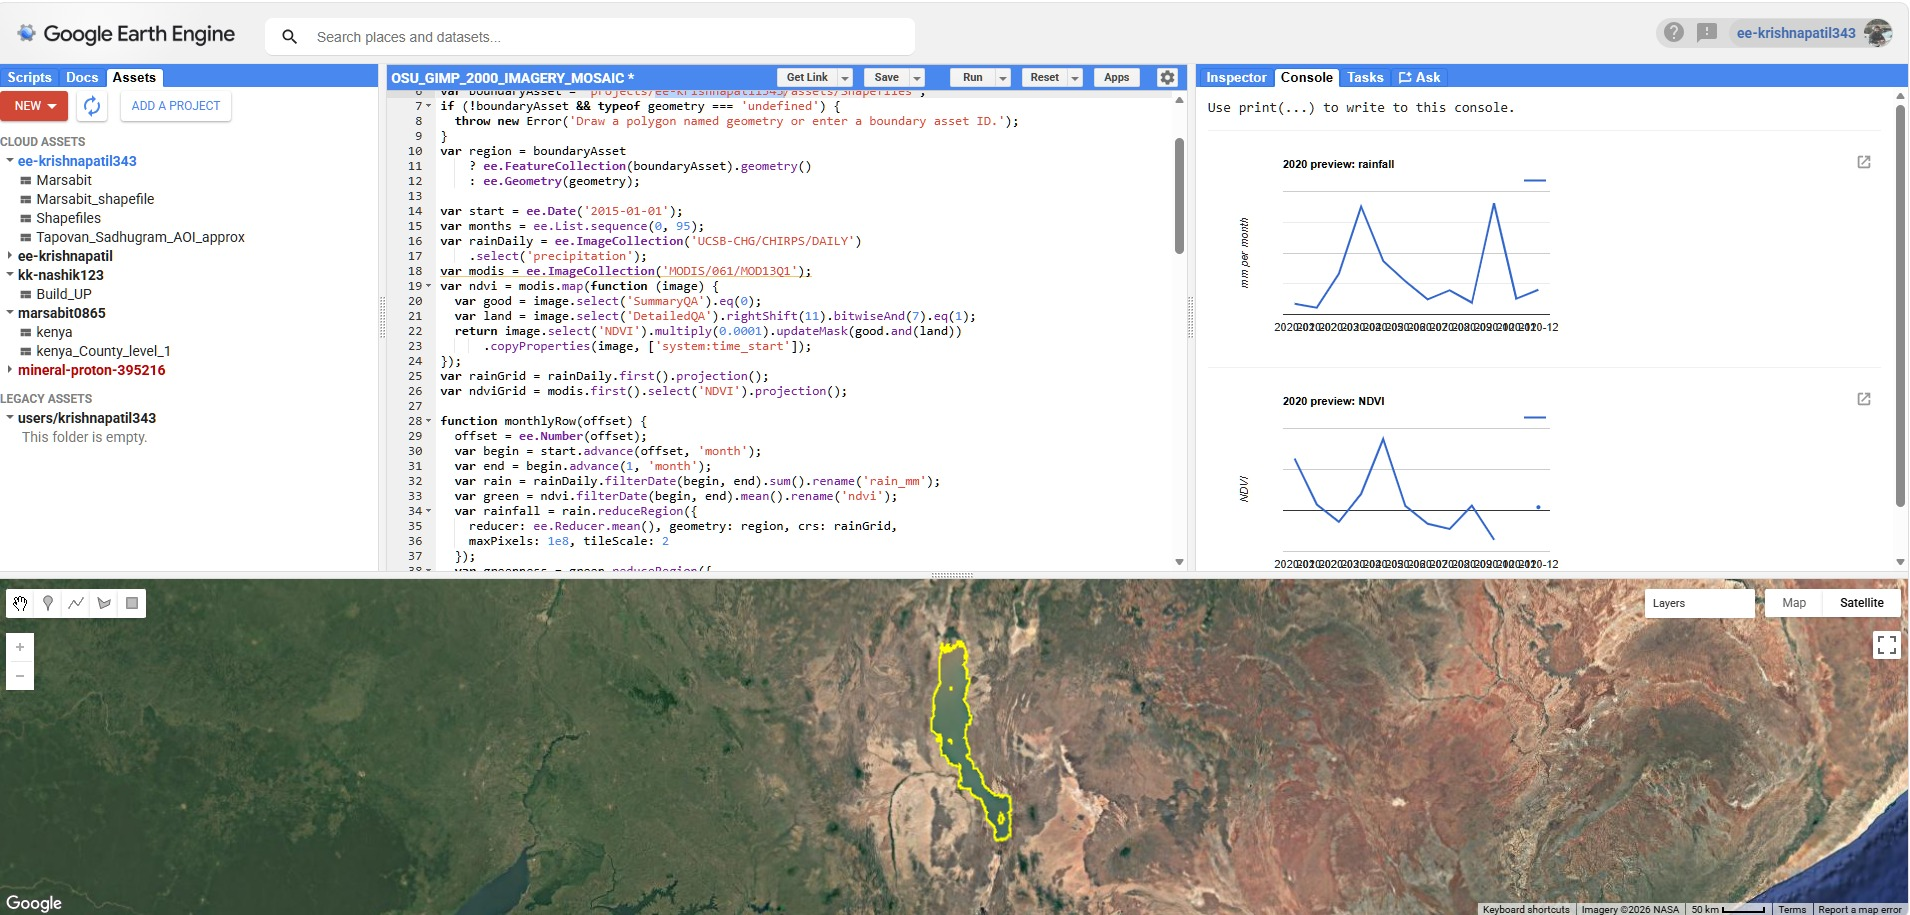

*Figure 1. The supplied example shows the Code Editor, with **Assets** at left, **Save** and **Run** above the code, **Console** and **Tasks** at right, and the map below. The yellow outline is the lake boundary used to demonstrate the interface. For the lag analysis, draw or upload a rangeland polygon on land. Your charts will depend on your boundary.*

## 2 Choose your study area

Choose one method.

- **Draw a polygon.** Search for North Turkana, switch the map to Satellite and draw a compact rectangle or polygon on rangeland. Check that the imported geometry is named `geometry`. Leave `boundaryAsset` empty.
- **Use a shapefile.** In **Assets → NEW**, choose the shapefile table upload option. Upload the ZIP with matching `.shp`, `.shx`, `.dbf` and `.prj` files. Wait for ingestion to finish, open the asset and paste its ID into `boundaryAsset`. Use a valid polygon dataset you have permission to read. [Earth Engine table upload guide](https://developers.google.com/earth-engine/guides/table_upload)

If both are present, the script uses the asset. Record the site name and describe the land cover. Avoid the lake, irrigated plots and major river channels for this exercise. Save the script again after setting the boundary.

```javascript
var boundaryAsset = '';
if (!boundaryAsset && typeof geometry === 'undefined') {
  throw new Error('Draw a polygon named geometry or enter a boundary asset ID.');
}
var region = boundaryAsset
    ? ee.FeatureCollection(boundaryAsset).geometry()
    : ee.Geometry(geometry);
```

## 3 Load the two datasets

`ee.ImageCollection` gives a collection of dated images. CHIRPS supplies daily precipitation depth on a 0.05° grid. MODIS Terra MOD13Q1 v6.1 supplies 16-day NDVI composites at 250 m. `select` picks a band and `map` applies the same screening to every MODIS image.

`SummaryQA == 0` keeps good-quality observations. Bits 11–13 of `DetailedQA` identify land and water. The shift and mask extract those bits, and `eq(1)` keeps land. The factor `0.0001` converts the stored values to unitless NDVI. `copyProperties` keeps the timestamp for grouping composites by month. Each product retains its own grid for area averages.

[CHIRPS dataset](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY) · [MODIS dataset and quality flags](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1)

```javascript
var start = ee.Date('2015-01-01');
var months = ee.List.sequence(0, 95);
var rainDaily = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
    .select('precipitation');
var modis = ee.ImageCollection('MODIS/061/MOD13Q1');
var ndvi = modis.map(function (image) {
  var good = image.select('SummaryQA').eq(0);
  var land = image.select('DetailedQA').rightShift(11).bitwiseAnd(7).eq(1);
  return image.select('NDVI').multiply(0.0001).updateMask(good.and(land))
      .copyProperties(image, ['system:time_start']);
});
var rainGrid = rainDaily.first().projection();
var ndviGrid = modis.first().select('NDVI').projection();
```

## 4 Build the monthly table

Each offset corresponds to one calendar month. `filterDate(begin, end)` selects observations from the start of that month up to the start of the next. The script **sums** daily rainfall into mm per month and **averages** valid NDVI composites by timestamp month. `reduceRegion` calculates a spatial mean over the selected polygon for each product on its own grid. It does not create finer rainfall detail.

The result is one feature per month with rainfall, NDVI and a month label. All calendar rows stay in the table. An empty NDVI value means there was no usable value for that month and boundary. Keep it blank.

```javascript
function monthlyRow(offset) {
  offset = ee.Number(offset);
  var begin = start.advance(offset, 'month');
  var end = begin.advance(1, 'month');
  var rain = rainDaily.filterDate(begin, end).sum().rename('rain_mm');
  var green = ndvi.filterDate(begin, end).mean().rename('ndvi');
  var rainfall = rain.reduceRegion({
    reducer: ee.Reducer.mean(), geometry: region, crs: rainGrid,
    maxPixels: 1e8, tileScale: 2
  });
  var greenness = green.reduceRegion({
    reducer: ee.Reducer.mean(), geometry: region, crs: ndviGrid,
    maxPixels: 1e8, tileScale: 2
  });
  return ee.Feature(null, rainfall.combine(greenness)).set({
    offset: offset, month: begin.format('YYYY-MM'), calendar_month: begin.get('month')
  });
}
var monthly = ee.FeatureCollection(months.map(monthlyRow)).sort('offset');
```

## 5 Run the script and inspect the preview

Click **Run**. Check the yellow outline on the satellite map and inspect the April 2020 NDVI layer. Open **Console** to see two **2020 preview charts**, one for rainfall and one for NDVI. The full export covers 2015–2022. If chart labels overlap, use the chart's expand control.

Check that the site is on land, rainfall is nonnegative and gaps in the NDVI chart are plausible. If the site has too few valid land pixels, choose another rangeland polygon, save, then rerun. Capture the boundary map and Console charts for your report.

```javascript
Map.setOptions('SATELLITE');
Map.centerObject(region, 11);
Map.addLayer(ndvi.filterDate('2020-04-01', '2020-05-01').mean().clip(region),
    {min: 0, max: 0.5, palette: ['f5e8c7', '78b56c', '155d27']}, 'April 2020 NDVI');
Map.addLayer(ee.FeatureCollection([ee.Feature(region)]).style({
  color: 'FFFF00', fillColor: '00000000', width: 2
}), {}, 'Study boundary');

var preview = ee.FeatureCollection(ee.List.sequence(60, 71).map(monthlyRow)).sort('offset');
print(ui.Chart.feature.byFeature(preview, 'month', ['rain_mm'])
    .setOptions({title: '2020 preview: rainfall', vAxis: {title: 'mm per month'}}));
print(ui.Chart.feature.byFeature(preview, 'month', ['ndvi'])
    .setOptions({title: '2020 preview: NDVI', vAxis: {title: 'NDVI'}, interpolateNulls: false}));
```

## 6 Compare raw and anomaly lags

A lag of **0** pairs January rainfall with January NDVI. A lag of **1** pairs January rainfall with February NDVI. The script joins rows by their calendar offsets, so a missing month does not shift the pairing. It uses only pairs with both values present and exports Pearson correlation and the number of valid pairs.

An anomaly is the observed value minus the average for the same calendar month across the study period. The script calculates separate rainfall and NDVI baselines, using available observations for each variable, before pairing. Compare the raw and anomaly results. If the raw peak is strong but the anomaly peak is weak, shared seasonality may explain some of the association. A weak or broad peak leaves the response time uncertain.

```javascript
function lagStats(rainRows, greenRows, rainBand, greenBand, lag) {
  var earlier = rainRows.filter(ee.Filter.notNull([rainBand])).map(function (row) {
    return row.set('target_offset', ee.Number(row.get('offset')).add(lag));
  });
  var later = greenRows.filter(ee.Filter.notNull([greenBand]));
  var pairs = ee.FeatureCollection(ee.Join.inner().apply(earlier, later,
      ee.Filter.equals({leftField: 'target_offset', rightField: 'offset'})))
      .map(function (pair) {
        return ee.Feature(null, {
          x: ee.Feature(pair.get('primary')).get(rainBand),
          y: ee.Feature(pair.get('secondary')).get(greenBand)
        });
      });
  var count = pairs.size();
  var r = ee.Algorithms.If(count.gte(2), pairs.reduceColumns({
    reducer: ee.Reducer.pearsonsCorrelation(), selectors: ['x', 'y']
  }).get('correlation'), null);
  return ee.Dictionary({r: r, pairs: count});
}
```

## 7 Export and download the data

1. After running the script, open **Tasks** beside Console. The script creates two export tasks. Click **Run** beside `Turkana_monthly_rain_ndvi`, check the destination and file name, then click **Run** in the dialog.
2. Wait for the task to complete. Start `Turkana_lag_results` the same way. If a task fails, open its details and record the error message. Check the boundary and task configuration before retrying.
3. Open [Google Drive](https://drive.google.com/) with the same account and find **My Drive → Turkana NDVI Course**, or the folder you chose in the task. Right-click each CSV and choose **Download**. Save both in your project folder with the boundary screenshot and a note identifying your site.
4. Open the CSVs to check their contents. The monthly table should have 96 rows plus headers, with `month`, `rain_mm` and `ndvi`. The lag table should have five rows plus headers, with lag, raw and anomaly correlations, and valid pair counts. Keep missing values blank. A blank correlation can occur when a lag has too few usable pairs or the paired series has no variability.

The Tasks exports run separately from the Console preview. An export only starts after you confirm it in Tasks. [Earth Engine CSV export reference](https://developers.google.com/earth-engine/apidocs/export-table-todrive)

```javascript
Export.table.toDrive({
  collection: monthly, description: 'Turkana_monthly_rain_ndvi',
  folder: 'Turkana NDVI Course', fileFormat: 'CSV',
  selectors: ['month', 'rain_mm', 'ndvi']
});
```

## 8 What to hand in

Submit the saved script or a Code Editor script link accessible to your instructor, both CSVs and a short report. Include the study boundary and its rationale, the rainfall and NDVI preview charts, and a comparison of the raw and anomaly lags with valid pair counts. Explain whether the results support a clear delay and give one limitation of the site or observations. If you used a private asset, provide the boundary separately or make sure your instructor can read it.